# Exercice 2 : Iris avec un MLP

In [1]:
%pip install numpy scikit-learn tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │              40 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

Test Accuracy: 90.00%


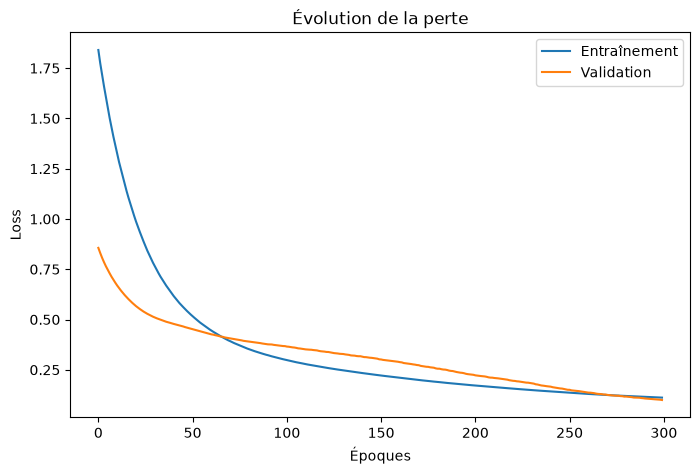

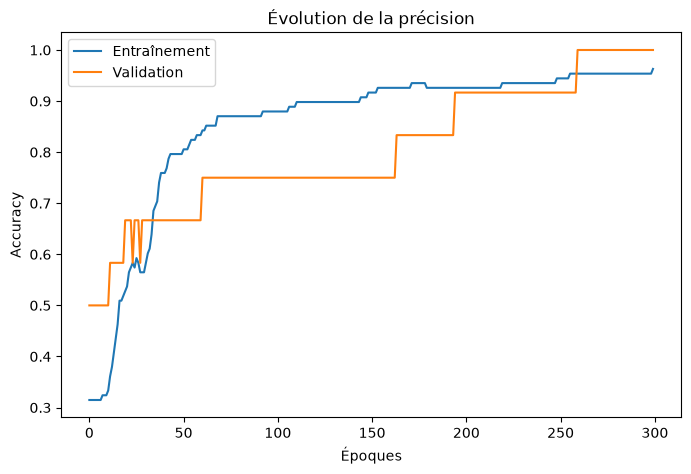

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

X, y = load_iris(return_X_y=True)           # 4 features, classes 0, 1, 2

# 1. on sépare d'abord
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# 2. on ajuste le scaler sur le train uniquement
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    Input(shape=(4,)),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax"),
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",   # y_train contient 0, 1, 2 (pas de one-hot)
              metrics=["accuracy"])
model.summary()

history = model.fit(X_train, y_train, epochs=300, batch_size=16,
                    validation_split=0.1, verbose=0)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Graphique 1 : Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Évolution de la perte")
plt.legend()
plt.show()


# Graphique 2 : Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Entraînement")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.title("Évolution de la précision")
plt.legend()
plt.show()

In [3]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

titanic = sns.load_dataset("titanic")
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X, y = titanic[features], titanic["survived"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# 1. valeurs manquantes : on utilise les statistiques du train
fill = {"age": X_train["age"].median(), "embarked": X_train["embarked"].mode()[0]}
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

# 2. variables catégorielles (mêmes colonnes pour train et test)
cat = ["sex", "embarked", "pclass"]
X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 3. normalisation des colonnes numériques (fit sur le train)
num = ["age", "fare"]
scaler = StandardScaler().fit(X_train[num])
X_train[num] = scaler.transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

# 4. conversion en tableaux numpy et vérification des dimensions
X_train = X_train.values.astype("float32")
X_test = X_test.values.astype("float32")
print("Shape X_train:", X_train.shape, "| Shape X_test:", X_test.shape)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.1, callbacks=[early], verbose=0)

pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, pred))

Shape X_train: (712, 9) | Shape X_test: (179, 9)
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
              precision    recall  f1-score   support

           0       0.80      0.91      0.85       110
           1       0.81      0.64      0.72        69

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



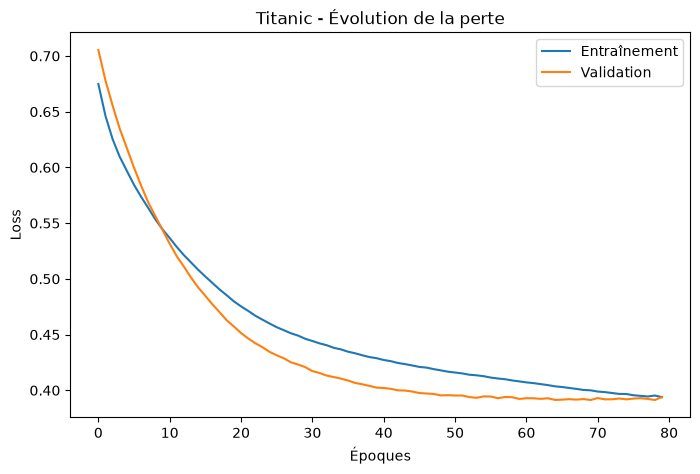

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Titanic - Évolution de la perte")
plt.legend()
plt.show()

### 4 Neuronnes

In [6]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(4, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.1, callbacks=[early], verbose=0)

pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
              precision    recall  f1-score   support

           0       0.79      0.95      0.86       110
           1       0.87      0.59      0.71        69

    accuracy                           0.81       179
   macro avg       0.83      0.77      0.78       179
weighted avg       0.82      0.81      0.80       179



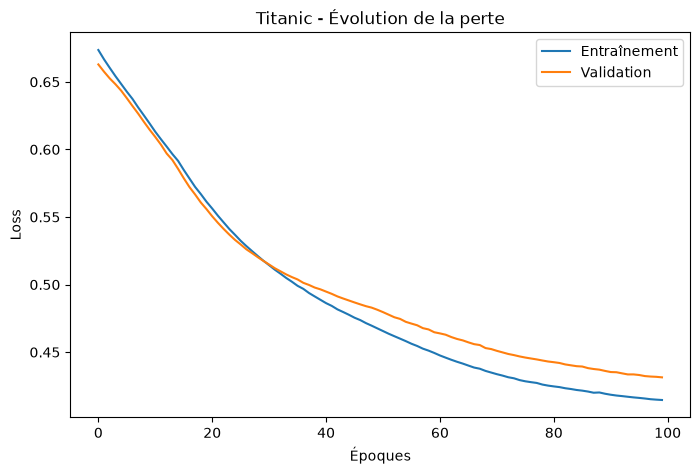

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Titanic - Évolution de la perte")
plt.legend()
plt.show()

### 64 Neuronnes

In [8]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.1, callbacks=[early], verbose=0)

pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
              precision    recall  f1-score   support

           0       0.80      0.92      0.85       110
           1       0.83      0.62      0.71        69

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



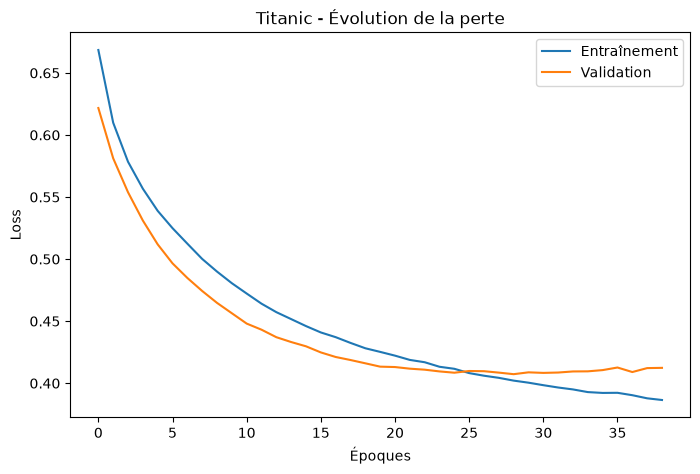

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Titanic - Évolution de la perte")
plt.legend()
plt.show()